# 3.1 Trends around precipitation events

This notebook looks at changes in no2 and soil conditions during the seven days before and after precipitation events that come after an extended dry period. Precipitation pulse events are identified independently within each grid cell using a seven-day antecedent dry-period threshold and a minimum hourly precipitation rate.

For each detected event, the notebook:

- extracts a ±7-day event window
- calculates a preceding seven-day rolling NO$_2$ background
- normalizes NO$_2$ observations to the background value at the event time
- constructs event-aligned composites of precipitation, water-filled pore space, NO$_2$, surface temperature, and soil temperature
- calculates 95% confidence intervals around the composite means
- creates figures


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import warnings


In [3]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [4]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
5,36.05,-90.45,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,0.000000,0.0,83.333333,0.000000,15.277778,Arkansas
6,36.05,-90.35,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,1.515152,0.0,0.0,0.0,6.818182,0.0,15.151515,5.303030,25.757576,Arkansas


In [5]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

# detecting dry spell events

In [6]:
def detect_pulses(df, dry_days=7, dry_sum_thresh_mm=2.5, rain_hourly_thresh=2.5):
    d = df.copy()
    d['datetime'] = pd.to_datetime(d['datetime'])
    d = d.sort_values(['grid_lat', 'grid_lon', 'datetime'])
    d['h_precip_mm'] = pd.to_numeric(d['h_precip_mm'], errors='coerce').fillna(0)

    dry_hours = int(dry_days * 24)
    out = []

    for (lat, lon), g in d.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()

        roll_sum = g['h_precip_mm'].rolling(dry_hours, min_periods=dry_hours).sum()
        g['dry_window'] = (roll_sum < dry_sum_thresh_mm).astype('boolean')
        prev_dry = g['dry_window'].shift(1, fill_value=False)

        g['pulse_start'] = ((g['h_precip_mm'] > rain_hourly_thresh) & prev_dry).astype('boolean')
        out.append(g.reset_index())

    return pd.concat(out, ignore_index=True)

In [7]:
pulses = detect_pulses(df,dry_days=7,dry_sum_thresh_mm=2.5,rain_hourly_thresh=5)

n_pulses = int(pulses['pulse_start'].sum())
print(f"Total pulses detected: {n_pulses:,}")

Total pulses detected: 459


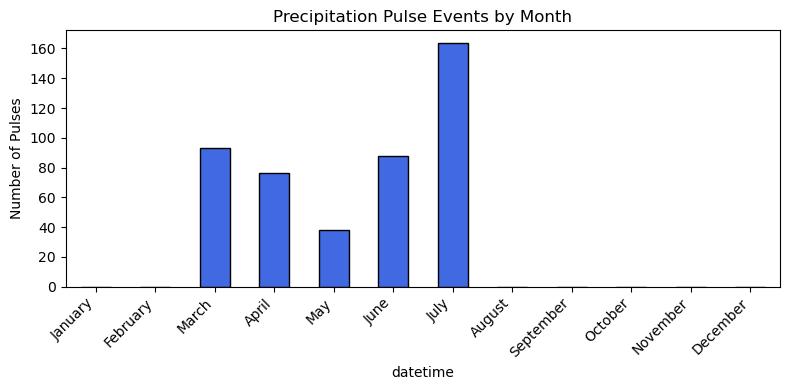

In [8]:
#inspect pulses by month 
pulse_times = pulses.loc[pulses['pulse_start'], 'datetime']
month_counts = pulse_times.dt.month_name().value_counts().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December']
)
plt.figure(figsize=(8, 4))
month_counts.plot(kind='bar', color='royalblue', edgecolor='black')
plt.ylabel('Number of Pulses')
plt.title('Precipitation Pulse Events by Month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [9]:
def build_event_windows(df, window_days=3):
    df = df.sort_values(['grid_lat', 'grid_lon', 'datetime']).copy()
    df['datetime'] = pd.to_datetime(df['datetime'])

    window = pd.Timedelta(days=window_days)
    events = []
    event_id = 0

    for (lat, lon), g in df.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()
        pulse_times = g.index[g['pulse_start'].fillna(False)]

        for t in pulse_times:
            sub = g.loc[t - window : t + window].copy()
            if sub.empty:
                continue
            sub['event_id'] = event_id
            sub['event_time'] = t
            sub['lag_hours'] = ((sub.index - t).total_seconds() // 3600).astype(int)
            sub['grid_lat'] = lat
            sub['grid_lon'] = lon
            events.append(sub.reset_index())
            event_id += 1

    return pd.concat(events, ignore_index=True) if events else pd.DataFrame()

In [10]:
events = build_event_windows(pulses, window_days=7)
print(f"Event windows built: {events['event_id'].nunique():,} events, {len(events):,} rows")

Event windows built: 459 events, 150,374 rows


# Add rolling no2 background 
For each grid cell and hour, compute the mean NO₂ over the preceding `bg_days` days (excluding the current hour). This is the pre-event background.

In [11]:
def add_no2_rolling_background(df, no2_col='no2_mean', bg_days=7, min_obs=12):
    d = df.copy()
    d['datetime'] = pd.to_datetime(d['datetime'])
    d = d.sort_values(['grid_lat', 'grid_lon', 'datetime'])

    out = []
    for (lat, lon), g in d.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()
        s = g[no2_col]

        bg_mean = s.rolling(f'{bg_days}D').mean().shift(1)
        bg_cnt = s.rolling(f'{bg_days}D').count().shift(1)
        bg_mean = bg_mean.where(bg_cnt >= min_obs)

        g[f'{no2_col}_bg'] = bg_mean
        out.append(g.reset_index())

    return pd.concat(out, ignore_index=True)

In [12]:
events_bg = add_no2_rolling_background(events, no2_col='no2_mean', bg_days=7, min_obs=12)
print(f"Background coverage: {events_bg['no2_mean_bg'].notna().mean():.1%} of rows have a valid bg")

Background coverage: 34.7% of rows have a valid bg


# Normalize NO2 to background ratio 

In [13]:
def normalize_no2_to_ratio(events, no2_col='no2_mean'):
    e = events.copy()
    if e.empty:
        return e

    bg_col = f'{no2_col}_bg'

    def _norm(g):
        bg0_rows = g.loc[g['lag_hours'] == 0, bg_col]
        bg0 = bg0_rows.iloc[0] if len(bg0_rows) else np.nan
        g['no2_bg0'] = bg0
        if pd.notna(bg0) and bg0 != 0:
            g['no2_norm'] = g[no2_col] / bg0
        else:
            g['no2_norm'] = np.nan
        return g

    e = e.groupby('event_id', group_keys=False).apply(_norm)

    # Drop events without a valid background
    valid_ids = e.loc[(e['lag_hours'] == 0) & (e['no2_bg0'].notna()), 'event_id'].unique()
    e = e[e['event_id'].isin(valid_ids)]
    print(f"Events retained after normalization: {e['event_id'].nunique():,}")
    return e

In [14]:
events_norm = normalize_no2_to_ratio(events_bg)

Events retained after normalization: 228


# build composites (mean and SD) 

In [15]:
events.head(5)

,datetime,grid_lat,grid_lon,h_precip_mm,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,dry_window,event_id,event_time,lag_hours
0,2024-06-26 19:00:00,37.05,-89.55,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,29.166667,0.0,13.888889,0.0,0.0,Missouri,False,0,2024-07-03 19:00:00,-168
1,2024-06-26 20:00:00,37.05,-89.55,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,29.166667,0.0,13.888889,0.0,0.0,Missouri,False,0,2024-07-03 19:00:00,-167
2,2024-06-26 21:00:00,37.05,-89.55,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,29.166667,0.0,13.888889,0.0,0.0,Missouri,False,0,2024-07-03 19:00:00,-166
3,2024-06-26 22:00:00,37.05,-89.55,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,29.166667,0.0,13.888889,0.0,0.0,Missouri,False,0,2024-07-03 19:00:00,-165
4,2024-06-26 23:00:00,37.05,-89.55,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,29.166667,0.0,13.888889,0.0,0.0,Missouri,False,0,2024-07-03 19:00:00,-164


In [16]:
def build_composite(events, vars_to_comp=('no2_norm', 'WFPS_c', 'h_precip_mm','surface_temp','soil_temp_layer1')):
    if events.empty:
        return pd.DataFrame()

    comp = (events.groupby('lag_hours')[list(vars_to_comp)].agg(['mean', 'std', 'count']).sort_index())
    comp.columns = ['_'.join(c) for c in comp.columns]
    return comp.reset_index()

In [17]:
comp_raw = build_composite(events_norm, 
                           vars_to_comp=('no2_norm', 'WFPS_c', 'h_precip_mm','surface_temp','soil_temp_layer1'))
print(f"Composite has {len(comp_raw)} lag-hour rows")
comp_raw.head()

Composite has 337 lag-hour rows


,lag_hours,no2_norm_mean,no2_norm_std,no2_norm_count,WFPS_c_mean,WFPS_c_std,WFPS_c_count,h_precip_mm_mean,h_precip_mm_std,h_precip_mm_count,surface_temp_mean,surface_temp_std,surface_temp_count,soil_temp_layer1_mean,soil_temp_layer1_std,soil_temp_layer1_count
0,-168,1.076906,0.379264,38,0.607157,0.136098,228,0.008443,0.063335,228,292.801666,7.543347,228,291.686768,5.643435,228
1,-167,1.048878,0.347662,34,0.607120,0.135897,228,0.003114,0.022369,228,292.663544,7.744279,228,291.727295,5.825704,228
2,-166,1.040036,0.329949,31,0.606190,0.137178,229,0.000175,0.001805,229,292.448853,7.826921,229,291.745941,5.983210,229
3,-165,0.953276,0.312247,26,0.605318,0.138528,230,0.000761,0.006522,230,292.213898,7.743620,230,291.726959,6.100093,230
4,-164,1.094817,0.308467,21,0.607685,0.138413,228,0.007105,0.050092,228,291.876923,7.499007,228,291.611786,6.186028,228


# building confidence intervals surrounding events

In [18]:
def build_ci_cols(df, mean_col, std_col, n_col, out_prefix, z=1.96):
    n = df[n_col].clip(lower=1).astype(float)
    sem = df[std_col].astype(float) /np.sqrt(n)
    m = df[mean_col].astype(float)
    return pd.DataFrame({
        f'{out_prefix}_mean_s': m,
        f'{out_prefix}_lo_s': m - z * sem,
        f'{out_prefix}_hi_s': m + z * sem})

In [19]:
comp = comp_raw[['lag_hours']].copy()

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='h_precip_mm_mean', std_col='h_precip_mm_std', n_col='h_precip_mm_count',
    out_prefix='h_precip_mm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='WFPS_c_mean', std_col='WFPS_c_std', n_col='WFPS_c_count',
    out_prefix='WFPS_c'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='no2_norm_mean', std_col='no2_norm_std', n_col='no2_norm_count',
    out_prefix='no2_norm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='surface_temp_mean', std_col='surface_temp_std', n_col='surface_temp_count',
    out_prefix='surface_temp_norm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='soil_temp_layer1_mean', std_col='soil_temp_layer1_std', n_col='soil_temp_layer1_count',
    out_prefix='soil_temp_layer1_norm'))

x = comp['lag_hours'].to_numpy()
print("comp columns:", comp.columns.tolist())
comp.head()

comp columns: ['lag_hours', 'h_precip_mm_mean_s', 'h_precip_mm_lo_s', 'h_precip_mm_hi_s', 'WFPS_c_mean_s', 'WFPS_c_lo_s', 'WFPS_c_hi_s', 'no2_norm_mean_s', 'no2_norm_lo_s', 'no2_norm_hi_s', 'surface_temp_norm_mean_s', 'surface_temp_norm_lo_s', 'surface_temp_norm_hi_s', 'soil_temp_layer1_norm_mean_s', 'soil_temp_layer1_norm_lo_s', 'soil_temp_layer1_norm_hi_s']


,lag_hours,h_precip_mm_mean_s,h_precip_mm_lo_s,h_precip_mm_hi_s,WFPS_c_mean_s,WFPS_c_lo_s,WFPS_c_hi_s,no2_norm_mean_s,no2_norm_lo_s,no2_norm_hi_s,surface_temp_norm_mean_s,surface_temp_norm_lo_s,surface_temp_norm_hi_s,soil_temp_layer1_norm_mean_s,soil_temp_layer1_norm_lo_s,soil_temp_layer1_norm_hi_s
0,-168,0.008443,0.000222,0.016664,0.607157,0.589491,0.624823,1.076906,0.956318,1.197495,292.801666,291.822508,293.780824,291.686768,290.954226,292.419309
1,-167,0.003114,0.000210,0.006018,0.607120,0.589480,0.624760,1.048878,0.932016,1.165741,292.663544,291.658304,293.668783,291.727295,290.971094,292.483496
2,-166,0.000175,-0.000059,0.000408,0.606190,0.588423,0.623957,1.040036,0.923886,1.156187,292.448853,291.435106,293.462599,291.745941,290.970993,292.520889
3,-165,0.000761,-0.000082,0.001604,0.605318,0.587415,0.623221,0.953276,0.833252,1.073300,292.213898,291.213123,293.214672,291.726959,290.938592,292.515327
4,-164,0.007105,0.000603,0.013607,0.607685,0.589719,0.625652,1.094817,0.962883,1.226750,291.876923,290.903520,292.850325,291.611786,290.808814,292.414758


# check sm range

In [20]:
wfps_min = comp['WFPS_c_lo_s'].min()
wfps_max = comp['WFPS_c_hi_s'].max()
print(f"WFPS range in composite: {wfps_min:.1f} – {wfps_max:.1f} %")

WFPS range in composite: 0.6 – 0.6 %


Saved: wfps_no2_figure.png


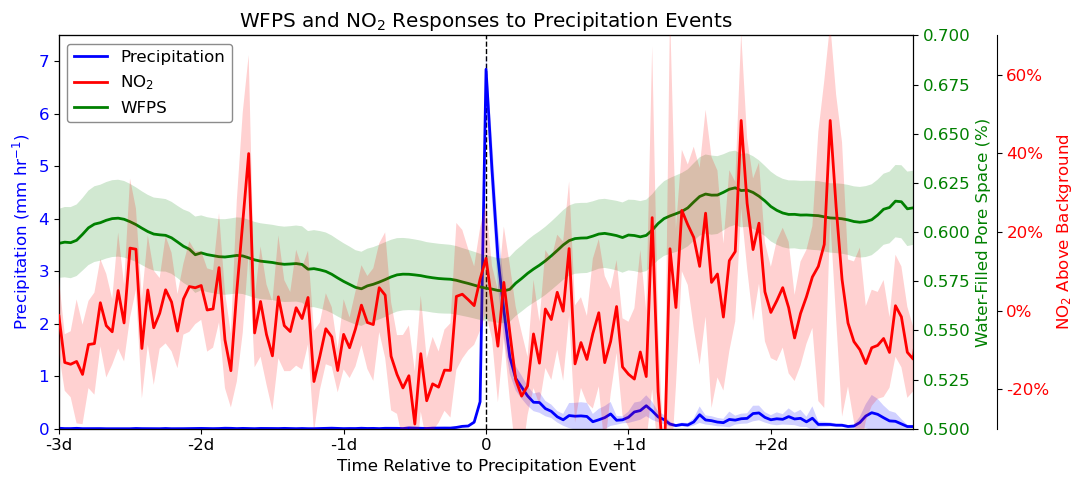

In [21]:
#set figure style 
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize']  = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

fig, ax_precip = plt.subplots(figsize=(11, 5))

#precip-- left axis, blue 
ax_precip.plot(x, comp['h_precip_mm_mean_s'], lw=2.0, color='blue',
               label='Precipitation (IMERG-GPM)', zorder=5)
ax_precip.fill_between(x, comp['h_precip_mm_lo_s'], comp['h_precip_mm_hi_s'],
                        color='blue', alpha=0.18, edgecolor='none', zorder=4)
ax_precip.set_ylabel('Precipitation (mm hr$^{-1}$)', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

#WFPS-- right axis, green
ax_wfps = ax_precip.twinx()
ax_wfps.plot(x, comp['WFPS_c_mean_s'], lw=2.0, color='green',
             label='WFPS (SMAP)', zorder=2)
ax_wfps.fill_between(x, comp['WFPS_c_lo_s'], comp['WFPS_c_hi_s'],
                     color='green', alpha=0.18, edgecolor='none', zorder=1)
ax_wfps.set_ylabel('Water-Filled Pore Space (%)', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.5,0.7)

#NO2 axis-- offset far-right axis, red
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))
ax_no2.plot(x, comp['no2_norm_mean_s'], lw=2.0, color='red',
            label='NO$_2$ (TEMPO)', zorder=8)
ax_no2.fill_between(x, comp['no2_norm_lo_s'], comp['no2_norm_hi_s'], color='red', alpha=0.18, edgecolor='none', zorder=7)
ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')
ax_no2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{(v-1)*100:.0f}%')) #formatted as % deviation from background (1.05 --> +5%
ax_no2.set_ylim(0.7, 1.7)

#labels and axes 
ax_precip.axvline(0, ls='--', c='k', lw=1)
ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-72, 72)
ax_precip.set_xticks(range(-72, 71, 24))
ax_precip.set_xticklabels([f'{h//24:+d}d' if h != 0 else '0' for h in range(-72, 72, 24)])
ax_precip.set_title(
    'WFPS and NO$_2$ Responses to Precipitation Events')

#combined legend
handles = [ax_precip.lines[0],  ax_no2.lines[0], ax_wfps.lines[0],]
labels = ['Precipitation', 'NO$_2$', 'WFPS',]
ax_precip.legend(handles, labels, loc='upper left',
                 frameon=True, facecolor='white', edgecolor='gray',
                 framealpha=0.9, fontsize=12)
plt.tight_layout()
plt.savefig('wfps_no2_figure.png', dpi=300, bbox_inches='tight')
print('Saved: wfps_no2_figure.png')

plt.show()

Saved: low_CF_scaled_wfps_no2_figure.png


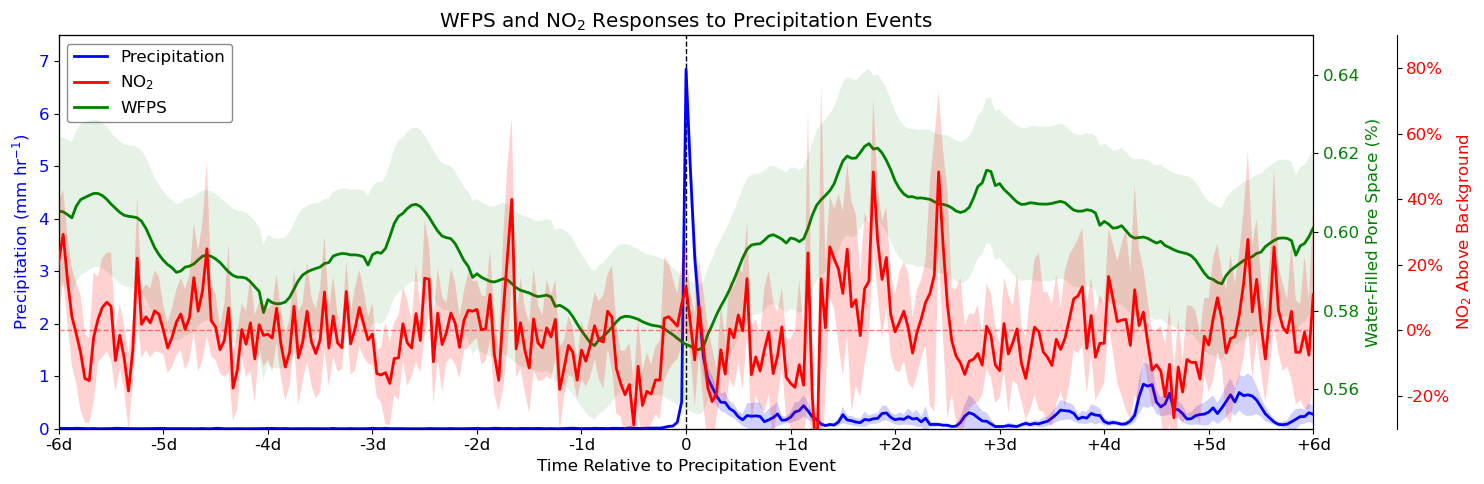

In [22]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

fig, ax_precip = plt.subplots(figsize=(15, 5))

#precip axis
p_line, = ax_precip.plot(x, comp['h_precip_mm_mean_s'], lw=2.0, color='blue',
                         label='Precipitation (IMERG-GPM)', zorder=5)
ax_precip.fill_between(x,comp['h_precip_mm_lo_s'],comp['h_precip_mm_hi_s'],color='blue',alpha=0.18, edgecolor='none',
                       zorder=4)
ax_precip.set_ylabel('Precipitation (mm hr$^{-1}$)', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

#wfps axis
ax_wfps = ax_precip.twinx()
w_line, = ax_wfps.plot(x, comp['WFPS_c_mean_s'], lw=2.0,color='green',label='WFPS (SMAP)', zorder=2)
ax_wfps.fill_between(x, comp['WFPS_c_lo_s'], comp['WFPS_c_hi_s'], color='green', alpha=0.10, edgecolor='none',  zorder=1)
ax_wfps.set_ylabel('Water-Filled Pore Space (%)', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.55, 0.65)

#no2 axis 
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))
n_line, = ax_no2.plot( x,comp['no2_norm_mean_s'], lw=2.0, color='red', label='NO$_2$ (TEMPO)',  zorder=8)
ax_no2.fill_between( x, comp['no2_norm_lo_s'], comp['no2_norm_hi_s'], color='red', alpha=0.18, edgecolor='none', zorder=7)

#reference line at background=1
ax_no2.axhline( 1.0, ls='--',  color='red', lw=1, alpha=0.5,zorder=6)
ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')

# format normalized NO2 as percent above/below background
ax_no2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%'))
ax_no2.set_ylim(0.7, 1.9)

#shard x axis and event label 
ax_precip.axvline(0, ls='--', color='k', lw=1)
ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-144, 144)
ax_precip.set_xticks(range(-144, 145, 24))
ax_precip.set_xticklabels([f'{h // 24:+d}d' if h != 0 else '0' for h in range(-144, 145, 24)])

ax_precip.set_title('WFPS and NO$_2$ Responses to Precipitation Events')

#legend 
ax_precip.legend( handles=[p_line, n_line, w_line], labels=['Precipitation', 'NO$_2$', 'WFPS'],
                 loc='upper left', frameon=True, facecolor='white', edgecolor='gray',framealpha=0.9, fontsize=12)

plt.tight_layout()
plt.savefig('wfps_no2_figure.png', dpi=300, bbox_inches='tight')
print('Saved: low_CF_scaled_wfps_no2_figure.png')
plt.show()

# save for PNAS

In [23]:
#PNAS figure settings
cm = 1 /2.54

# PNAS widths-- same as text column = 8.7 cm, medium wide = 11.4 cm, full wide = 17.8 cm
fig_width = 17.8 *cm
fig_height = 6.5 *cm

plt.rcParams.update(plt.rcParamsDefault)

plt.rcParams.update({
    #font sizes should be 6–12 pt according to template
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,

    #font embedding for pdf/eps
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600})

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: wfps_no2_figure_pnas.pdf
Saved: wfps_no2_figure_pnas.eps
Saved: wfps_no2_figure_pnas.png


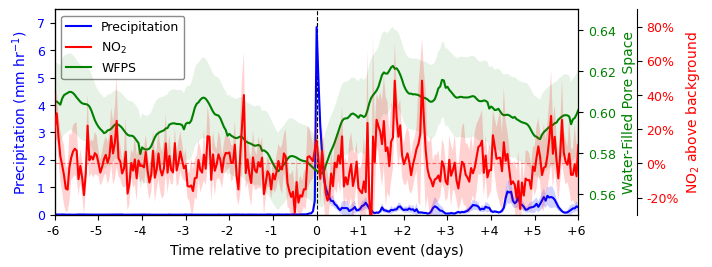

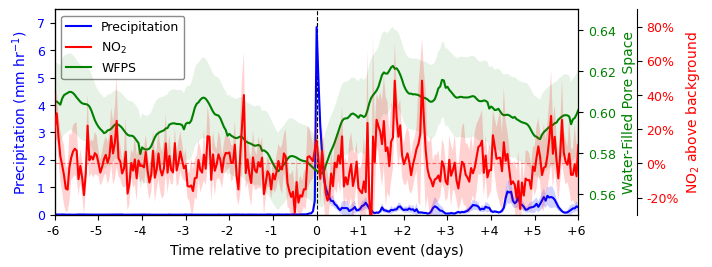

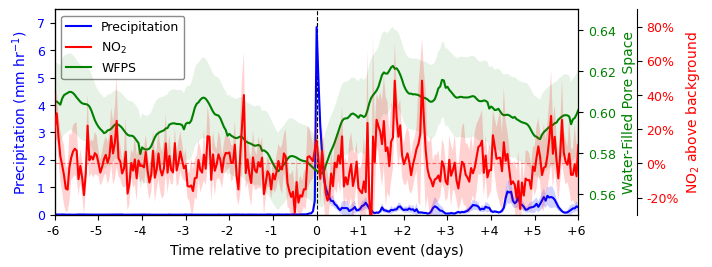

In [26]:
fig, ax_precip = plt.subplots(figsize=(fig_width, fig_height), constrained_layout=True)

#precip axis - blue
p_line, = ax_precip.plot(x,comp["h_precip_mm_mean_s"],lw=1.5,color="blue",
                         label="Precipitation",zorder=5)

ax_precip.fill_between(x,comp["h_precip_mm_lo_s"], comp["h_precip_mm_hi_s"],color="blue",
                       alpha=0.18, edgecolor="none", zorder=4)

ax_precip.set_ylabel("Precipitation (mm hr$^{-1}$)", color="blue")
ax_precip.tick_params(axis="y", labelcolor="blue")
ax_precip.set_ylim(bottom=0)

#WFPS - green
ax_wfps = ax_precip.twinx()

w_line, = ax_wfps.plot(x, comp["WFPS_c_mean_s"], lw=1.5, color="green",
                       label="WFPS",zorder=2)

ax_wfps.fill_between(x, comp["WFPS_c_lo_s"], comp["WFPS_c_hi_s"],color="green",
                     alpha=0.10, edgecolor="none", zorder=1)

ax_wfps.set_ylabel("Water-Filled Pore Space", color="green")
ax_wfps.tick_params(axis="y", labelcolor="green")
ax_wfps.set_ylim(0.55, 0.65)

#NO2 - red
ax_no2 = ax_precip.twinx()
ax_no2.spines["right"].set_position(("outward", 42))

n_line, = ax_no2.plot(x, comp["no2_norm_mean_s"], lw=1.5, color="red",
                      label="NO$_2$", zorder=8)

ax_no2.fill_between(x, comp["no2_norm_lo_s"], comp["no2_norm_hi_s"],color="red", alpha=0.18,
                    edgecolor="none", zorder=7)

ax_no2.axhline(1.0, ls="--", color="red",
               lw=0.8, alpha=0.5, zorder=6)

ax_no2.set_ylabel("NO$_2$ above background", color="red")
ax_no2.tick_params(axis="y", labelcolor="red")
ax_no2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{(v - 1) * 100:.0f}%"))
ax_no2.set_ylim(0.7, 1.9)

#shared x axis and lines
ax_precip.axvline(0, ls="--", color="black", lw=0.8)

ax_precip.set_xlabel("Time relative to precipitation event (days)")
ax_precip.set_xlim(-144, 144)
ax_precip.set_xticks(range(-144, 145, 24))
ax_precip.set_xticklabels(
    [f"{h // 24:+d} " if h != 0 else "0" for h in range(-144, 145, 24)]
)

#ax_precip.set_title("WFPS and NO$_2$ responses to precipitation events")

#legendd
ax_precip.legend(handles=[p_line, n_line, w_line], labels=["Precipitation", "NO$_2$", "WFPS"], 
                 loc="upper left", frameon=True, facecolor="white", edgecolor="gray",
                 framealpha=0.9,)

#save in pnas formats
fig.savefig("/global/home/users/toireasamarie/FINAL_Paper_Workflow/Paper Figures/wfps_no2_figure_pnas_fullwidth.pdf")
fig.savefig("/global/home/users/toireasamarie/FINAL_Paper_Workflow/Paper Figures/wfps_no2_figure_pnas_fullwidth.eps")

#also as png 
fig.savefig("/global/home/users/toireasamarie/FINAL_Paper_Workflow/Paper Figures/wfps_no2_figure_pnas_fullwidth.png", dpi=600)

print("Saved: wfps_no2_figure_pnas.pdf")
print("Saved: wfps_no2_figure_pnas.eps")
print("Saved: wfps_no2_figure_pnas.png")

plt.show()

In [27]:
import matplotlib.gridspec as gridspec

In [28]:
cm = 1 / 2.54
fig_width  = 17.8 * cm
fig_height = 12 * cm   # more height for stacked layout
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "font.size":        10,
    "axes.labelsize":   10,
    "axes.titlesize":   11,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "legend.fontsize":  9,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
    "svg.fonttype":     "none",
    "savefig.dpi":      600})

fig = plt.figure(figsize=(fig_width, fig_height), constrained_layout=True)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


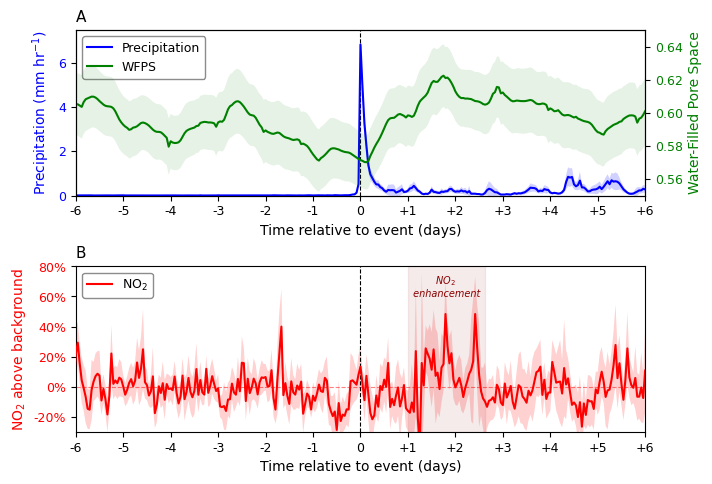

In [29]:
#Trying a two paneled stacked layout 
gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0)

#top panel is wfps and precipitation 
ax_precip = fig.add_subplot(gs[0])
ax_wfps = ax_precip.twinx()

p_line, = ax_precip.plot(x, comp["h_precip_mm_mean_s"], lw=1.5, 
                         color="blue", label="Precipitation", zorder=5)

ax_precip.fill_between(x, comp["h_precip_mm_lo_s"], comp["h_precip_mm_hi_s"], 
                       color="blue", alpha=0.18, edgecolor="none", zorder=4)

ax_precip.set_ylabel("Precipitation (mm hr$^{-1}$)", color="blue")
ax_precip.tick_params(axis="y", labelcolor="blue")
ax_precip.set_ylim(bottom=0)

w_line, = ax_wfps.plot(x, comp["WFPS_c_mean_s"], lw=1.5, 
                       color="green", label="WFPS", zorder=2)

ax_wfps.fill_between(x, comp["WFPS_c_lo_s"], comp["WFPS_c_hi_s"],
                     color="green", alpha=0.10, edgecolor="none", zorder=1)

ax_wfps.set_ylabel("Water-Filled Pore Space", color="green")
ax_wfps.tick_params(axis="y", labelcolor="green")
ax_wfps.set_ylim(0.55, 0.65)

ax_precip.axvline(0, ls="--", color="black", lw=0.8)
ax_precip.set_xlim(-144, 144)
ax_precip.set_xticks(range(-144, 145, 24))
ax_precip.set_xticklabels([f"{h // 24:+d}" if h != 0 else "0" for h in range(-144, 145, 24)])
ax_precip.set_xlabel("Time relative to event (days)")

ax_precip.legend(handles=[p_line, w_line], labels=["Precipitation", "WFPS"],
                 loc="upper left", frameon=True, facecolor="white", edgecolor="gray", framealpha=0.9)

ax_precip.set_title("A", loc="left")

#bottom panel is no2
ax_no2 = fig.add_subplot(gs[1])

n_line, = ax_no2.plot(x, comp["no2_norm_mean_s"], lw=1.5,
                      color="red", label="NO$_2$", zorder=3)
ax_no2.fill_between(x, comp["no2_norm_lo_s"], comp["no2_norm_hi_s"],
                    color="red", alpha=0.18, edgecolor="none", zorder=2)
ax_no2.axhline(1.0, ls="--", color="red", lw=0.8, alpha=0.5, zorder=1)

ax_no2.set_ylabel("NO$_2$ above background", color="red")
ax_no2.tick_params(axis="y", labelcolor="red")
ax_no2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{(v - 1) * 100:.0f}%"))
ax_no2.set_ylim(0.7, 1.8)

ax_no2.axvline(0, ls="--", color="black", lw=0.8)
ax_no2.set_xlim(-144, 144)
ax_no2.set_xticks(range(-144, 145, 24))
ax_no2.set_xticklabels([f"{h // 24:+d}" if h != 0 else "0" for h in range(-144, 145, 24)])
ax_no2.set_xlabel("Time relative to event (days)")

ax_no2.legend(handles=[n_line], labels=["NO$_2$"],  loc="upper left", frameon=True,
              facecolor="white", edgecolor="gray", framealpha=0.9)

ax_no2.set_title("B", loc="left")
ax_no2.axvspan(24, 63, color="darkred", alpha=0.08, zorder=0)
ax_no2.annotate("NO$_2$ \n enhancement", xy=(43, 1.75), ha="center", va="top",
                fontsize=7, color="darkred", style="italic")


#saving
base = "/global/home/users/toireasamarie/FINAL_Paper_Workflow/Paper Figures/wfps_no2_twopanel_pnas"
fig.savefig(base + ".pdf")
fig.savefig(base + ".eps")
fig.savefig(base + ".png", dpi=600)
plt.show()